# Week 6 on a Mac: "The Price is Right" with local models

The course notebooks (`day1.ipynb` ... `day5.ipynb`) need an HF token, Groq for the day 2 rewriting, four frontier
APIs on day 4 and OpenAI fine-tuning on day 5. None of those keys are in `.env`, but Ed's datasets are public on the
Hub, so the same five days run here with [local_pricer.py](local_pricer.py):

| course | here |
|--------|------|
| `login(hf_token)` | not needed - `ed-donner/items_lite` and the Amazon scrape are public |
| 8 Amazon categories, 820k items | Appliances only for day 1 (the full scrape is tens of GB; this disk has ~20 GB free) |
| Groq batch API with gpt-oss-20b | the same prompt on `llama3.2` / `qwen2.5:14b`, concurrent requests to Ollama |
| `items_full` (800k training items) | `items_lite` (20k) - its test set is the **same products** as the full test set, so the error numbers are comparable with Ed's |
| XGBoost | XGBoost, with torch imported first so it finds torch's bundled `libomp` (no `brew install libomp` needed) |
| GPT-4.1-nano, Claude, Gemini, Grok, GPT-5.1 | `llama3.2` (3B) and `qwen2.5:14b` on Ollama |
| fine-tuning gpt-4.1-nano through OpenAI | a LoRA adapter on `Qwen2.5-0.5B-Instruct`, trained on the Mac's GPU with peft |

`evaluate` is the course's `Tester` (same error metric, same first 200 test items) with one static chart instead of
two interactive plotly ones, and it keeps every score for the results chart at the end.

In [1]:
import random
import time
import csv
import json
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from datasets import load_dataset

import local_pricer as lp
from local_pricer import evaluate, load_items, RESULTS
from pricer.items import Item
from pricer.parser import parse

pd.set_option("display.max_colwidth", 200)
print("Ollama running:", lp.ollama_running(), "| device for torch:", lp.device())

Ollama running: True | device for torch: mps


## Day 1 – data curation

The raw scrape is [McAuley-Lab/Amazon-Reviews-2023](https://huggingface.co/datasets/McAuley-Lab/Amazon-Reviews-2023).
One category (Appliances, a 285 MB download) is enough to see every curation step; the other seven only add volume.

In [2]:
dataset = load_dataset("McAuley-Lab/Amazon-Reviews-2023", "raw_meta_Appliances", split="full", trust_remote_code=True)
print(f"Number of Appliances: {len(dataset):,}")
{k: (v[:120] + "..." if isinstance(v, str) and len(v) > 120 else v) for k, v in dataset[6].items() if k != "images"}

Number of Appliances: 94,327


{'main_category': 'Appliances',
 'title': 'WD12X10327 Rack Roller and stud assembly Kit (4 Pack) by AMI PARTS Replaces AP4980629 PS3486910 1811003',
 'average_rating': 4.6,
 'rating_number': 323,
 'features': ['【PARTS NUMBER】The WD12X10327 dishwasher top rack wheels and stud assembly Kit （4 pcs）',
  '【SCOPE OF APPLICATION】The dishwasher works with most top name brands,If you are not sure if part is correct, ask us in Customer questions & answers section or visiting the AMI PARTS storefront.We’re happy to help ensure you select the correct part for your Rack Roller and stud',
  '【REPLACES PART】1811003, AP4980629, WD12X0330, WD12X0356, WD12X0357, WD12X0383, WD12X0385, WD12X10327, WD12X330, WD12X356, WD12X357, WD12X383, WD12X385',
  '【FIXES SYMPTOMS】Door won’t close | Not cleaning dishes properly | Noisy | Door latch failure',
  '【QUALITY WARRANTY】The replacement part is made from durable high quality material and well-tested by manufacturer.For any reason you’re not satisfied,you can ask

In [3]:
# What's the most expensive item?
prices = []
for datapoint in dataset:
    try:
        prices.append((float(datapoint["price"]), datapoint["title"]))
    except ValueError:
        pass
max_price, max_title = max(prices)
print(f"{len(prices):,} of {len(dataset):,} datapoints have a price")
print(f"The most expensive item is {max_title[:100]} and it costs ${max_price:,.2f}")

46,726 of 94,327 datapoints have a price
The most expensive item is TurboChef BULLET Rapid Cook Electric Microwave Convection Oven and it costs $21,095.62


`pricer/parser.py` keeps items priced \$0.50–\$999.49 with at least 600 characters of description, strips part
numbers and noisy details, and caps the text at 4,000 characters.

In [4]:
items = [parse(datapoint, "Appliances") for datapoint in dataset]
items = [item for item in items if item is not None]
print(f"There are {len(items):,} items from {len(dataset):,} datapoints")
print(items[0].full[:700])

There are 35,307 items from 94,327 datapoints
Rack Roller and stud assembly Kit (4 Pack) by AMI PARTS Replaces   1811003
['【PARTS NUMBER】The  dishwasher top rack wheels and stud assembly Kit （4 pcs）', '【SCOPE OF 】The dishwasher works with most top name brands,If you are not sure if part is correct, ask us in Customer questions & answers section or visiting the AMI PARTS storefront.We’re happy to help ensure you select the correct part for your Rack Roller and stud', '【 PART】, , , , , , , , , , , , ', '【FIXES SYMPTOMS】Door won’t close | Not cleaning dishes properly | Noisy | Door latch failure', '【QUALITY WARRANTY】The replacement part is made from durable high quality material and well-tested by manufacturer.For any reason you’re not sat


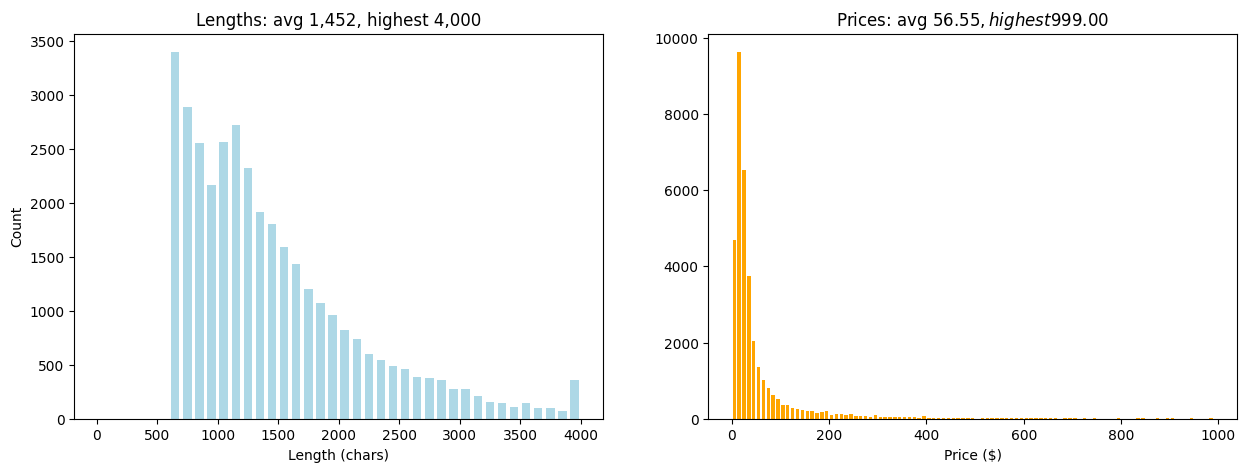

In [5]:
lengths = [len(item.full) for item in items]
prices = [item.price for item in items]

fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5))
left.hist(lengths, rwidth=0.7, color="lightblue", bins=range(0, 4100, 100))
left.set(title=f"Lengths: avg {np.mean(lengths):,.0f}, highest {max(lengths):,}", xlabel="Length (chars)", ylabel="Count")
right.hist(prices, rwidth=0.7, color="orange", bins=range(0, 1000, 10))
right.set(title=f"Prices: avg ${np.mean(prices):,.2f}, highest ${max(prices):,.2f}", xlabel="Price ($)")
plt.show()

Cheap items dominate. Ed deduplicates and then samples with weights proportional to price², which flattens the
price distribution so the model sees enough expensive products. The same step on Appliances alone:

After deduplication, we have 32,721 items


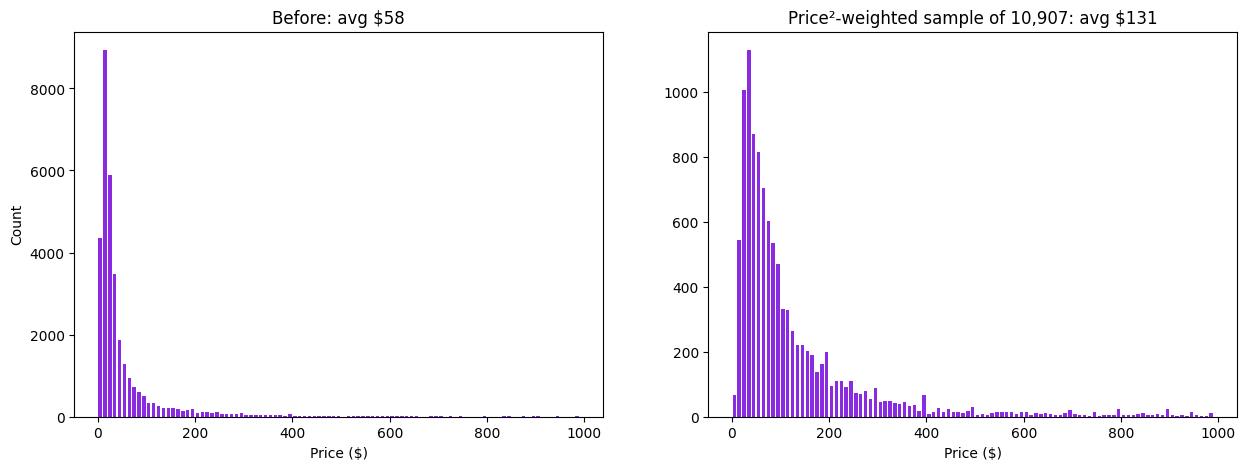

In [6]:
random.seed(42)
random.shuffle(items)
seen = set()
items = [x for x in items if not (x.title in seen or seen.add(x.title))]
seen = set()
items = [x for x in items if not (x.full in seen or seen.add(x.full))]
print(f"After deduplication, we have {len(items):,} items")

np.random.seed(42)
prices = np.array([it.price for it in items])
p = (prices - prices.min()) / (prices.max() - prices.min() + 1e-9)
w = p**2 / (p**2).sum()
sample = [items[i] for i in np.random.choice(len(items), size=len(items) // 3, replace=False, p=w)]

fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5), sharex=True)
left.hist(prices, rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
left.set(title=f"Before: avg ${prices.mean():,.0f}", xlabel="Price ($)", ylabel="Count")
right.hist([it.price for it in sample], rwidth=0.7, color="blueviolet", bins=range(0, 1000, 10))
right.set(title=f"Price²-weighted sample of {len(sample):,}: avg ${np.mean([it.price for it in sample]):,.0f}", xlabel="Price ($)")
plt.show()

### The curated dataset

From here on everything uses Ed's finished dataset, built from all eight categories and already rewritten on
day 2. The lite version has 20,000 training items.

Loaded 20,000 training items, 1,000 validation items, 1,000 test items


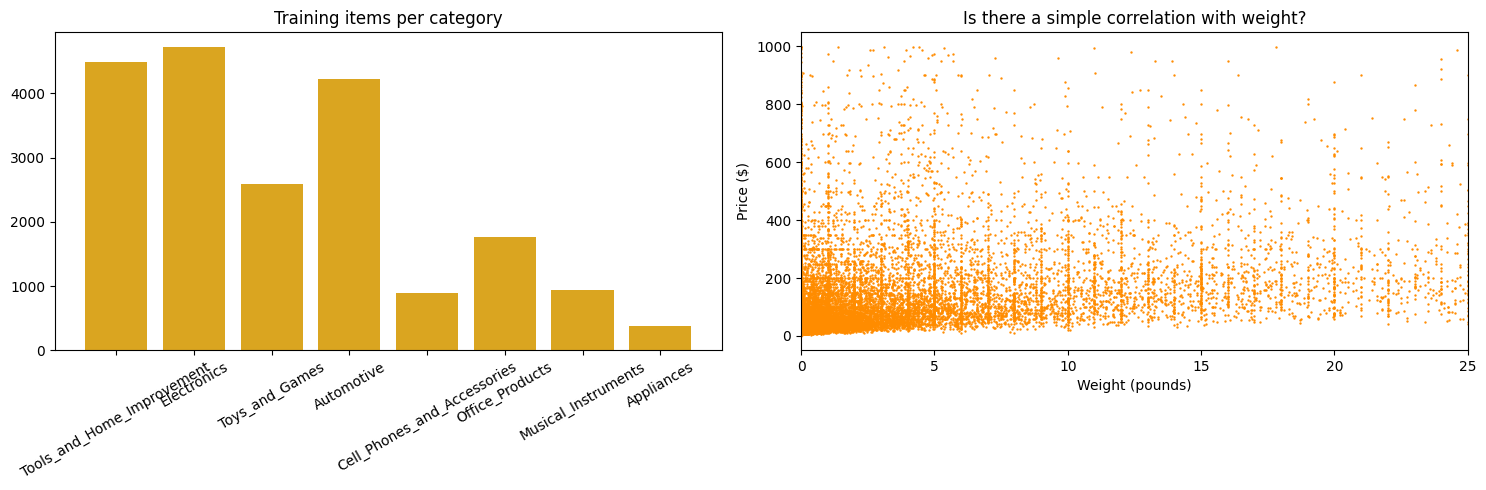

In [7]:
train, val, test = load_items(lite=True)
print(f"Loaded {len(train):,} training items, {len(val):,} validation items, {len(test):,} test items")

counts = Counter(item.category for item in train)
fig, (left, right) = plt.subplots(1, 2, figsize=(15, 5))
left.bar(list(counts), list(counts.values()), color="goldenrod")
left.set_title("Training items per category")
left.tick_params(axis="x", rotation=30)
right.scatter([it.weight for it in train], [it.price for it in train], s=0.5, color="darkorange")
right.set(xlim=(0, 25), title="Is there a simple correlation with weight?", xlabel="Weight (pounds)", ylabel="Price ($)")
plt.tight_layout()
plt.show()

## Day 2 – rewriting the products with an LLM

Ed sent 22,000 scraped pages through Groq's batch API (gpt-oss-20b) to get the short five-line summaries the rest
of the week trains on. `items_raw_lite` holds the same items before rewriting, in the same order, so a local model
can redo a few and be compared with Ed's summaries.

In [8]:
raw_train, raw_val, raw_test = Item.from_hub("ed-donner/items_raw_lite")
assert all(a.title == b.title for a, b in zip(raw_train, train))
print(lp.REWRITE_PROMPT)
print()
print(raw_train[0].full[:800])

Create a concise description of a product. Respond only in this format. Do not include part numbers.
Title: Rewritten short precise title
Category: eg Electronics
Brand: Brand name
Description: 1 sentence description
Details: 1 sentence on features

Schlage F59 AND 613 Andover Interior Knob with Deadbolt, Oil Rubbed Bronze (Interior Half Only)
['From the Manufacturer', "When you have a Schlage handleset on your front door, you ensure your security as well as your peace of mind. After all, we're the leader in security devices, trusted for over 85 years. All Schlage handlesets are precision engineered, featuring 100% solid"]
['Interior half only', 'Requires F58 to complete handle set', 'Non handed knob style', '4" minimum center to center door prep required for this two piece model.', 'Lifetime Mechanical and Finish Warranty']
{"Material": "Metal", "Brand": "", "Color": "Oil Rubbed Bronze", "Exterior Finish": "Bronze", "Special Feature": "Easy to Install", "Age Range (Description)": "Adu

In [9]:
sample = [item.model_copy() for item in raw_train[:12]]
timings = {}
summaries = {}
for model in ["llama3.2", "qwen2.5:14b"]:
    batch = [item.model_copy() for item in sample]
    timings[model] = lp.rewrite_many(batch, model=model)
    summaries[model] = [item.summary for item in batch]
    hours = timings[model] * 22_000 / 3600
    print(f"{model}: {timings[model]:.1f}s per item -> about {hours:.0f} hours for the 22,000 lite items")

  0%|          | 0/12 [00:00<?, ?it/s]

llama3.2: 1.4s per item -> about 8 hours for the 22,000 lite items


  0%|          | 0/12 [00:00<?, ?it/s]

qwen2.5:14b: 5.4s per item -> about 33 hours for the 22,000 lite items


In [10]:
for i in [0, 5]:
    print(f"===== {train[i].title[:80]}  (${train[i].price})")
    print("--- Ed (gpt-oss-20b via Groq):")
    print(train[i].summary)
    for model in summaries:
        print(f"--- {model}:")
        print(summaries[model][i])
    print()

===== Schlage F59 AND 613 Andover Interior Knob with Deadbolt, Oil Rubbed Bronze (Inte  ($64.3)
--- Ed (gpt-oss-20b via Groq):
Title: Schlage F59 & 613 Andover Interior Knob (Deadbolt Included)  
Category: Home Hardware  
Brand: Schlage  
Description: A single‑piece oil‑rubbed bronze knob that mounts to a deadbolt for secure, easy interior door use.  
Details: Designed for a 4" minimum center‑to‑center door prep, it offers a lifetime mechanical and finish warranty and comes ready for quick installation.
--- llama3.2:
Schlage Interior Knob with Deadbolt
Category: Home Security
Brand: Schlage
Description: A reliable and secure interior door handle with a deadbolt for added protection.
Details: Features a precision-engineered design with a lifetime mechanical and finish warranty.
--- qwen2.5:14b:
Title: Schlage Andover Interior Door Knob and Deadbolt Set
Category: Home Improvement
Brand: Schlage
Description: Secure and stylish interior door knob and deadbolt set.
Details: Oil-rubbed bronz

Both local models follow the format. Rewriting all of `items_lite` locally would take an afternoon (and `items_full`
weeks), which is exactly why Ed used a batch API - so the rest of this notebook keeps his summaries.

## Day 3 – evaluation, baselines and traditional ML

The score is the average absolute error in dollars over the first 200 test items.

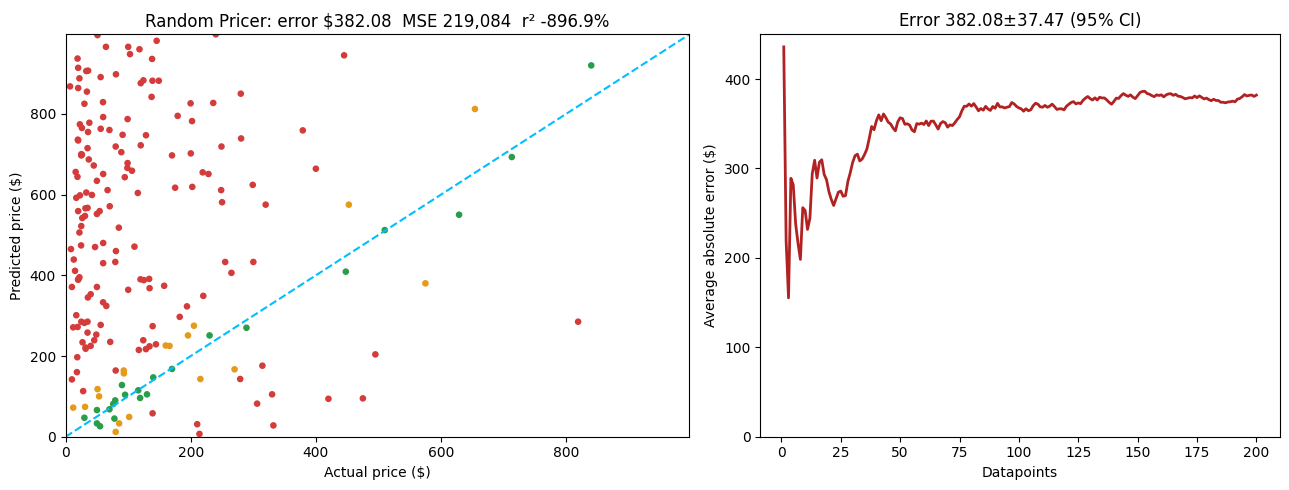

382.07885000000005

In [11]:
def random_pricer(item):
    return random.randrange(1, 1000)

random.seed(42)
evaluate(random_pricer, test)

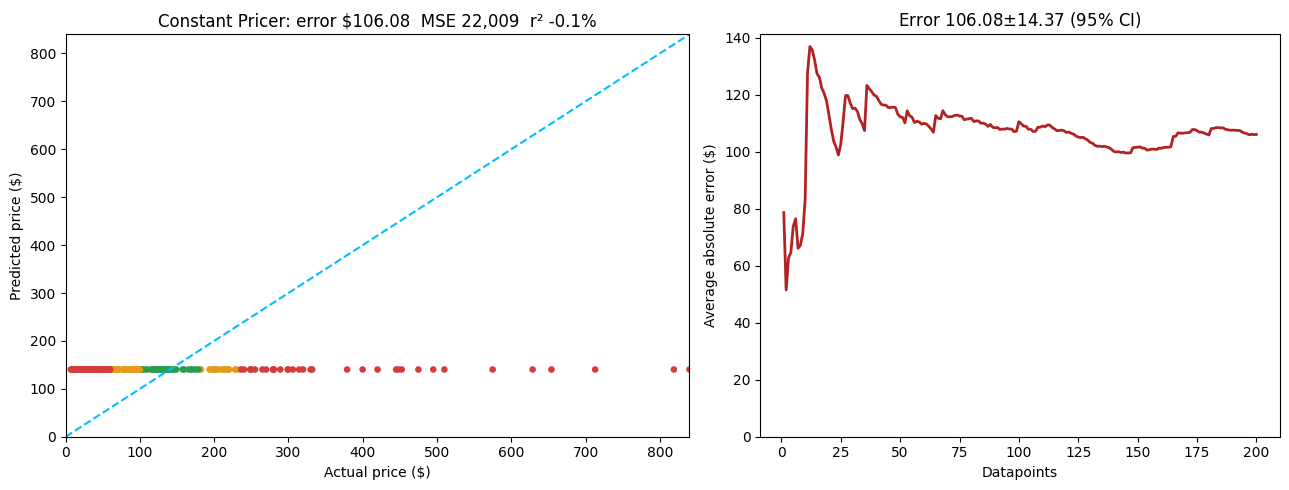

106.08424013

In [12]:
training_average = sum(item.price for item in train) / len(train)

def constant_pricer(item):
    return training_average

evaluate(constant_pricer, test)

{'weight': np.float64(3.569), 'weight_unknown': np.float64(20.902), 'text_length': np.float64(0.203)} intercept 40.91


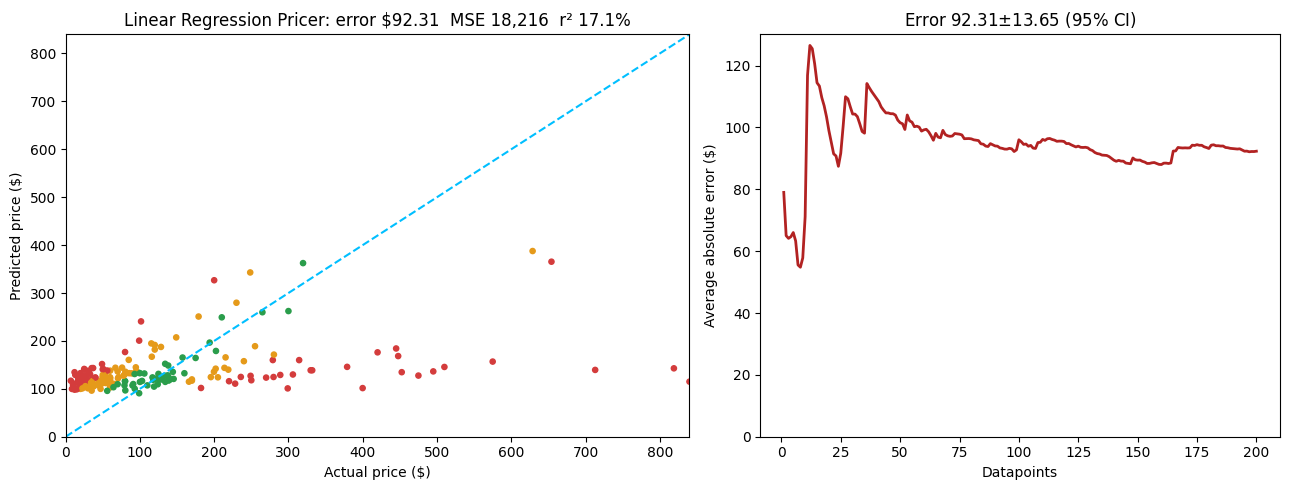

np.float64(92.31280875444331)

In [13]:
from sklearn.linear_model import LinearRegression

def get_features(item):
    return {"weight": item.weight, "weight_unknown": 1 if item.weight == 0 else 0, "text_length": len(item.summary)}

train_df = pd.DataFrame([get_features(item) for item in train])
model = LinearRegression().fit(train_df, [item.price for item in train])
print(dict(zip(train_df.columns, model.coef_.round(3))), "intercept", round(model.intercept_, 2))

def linear_regression_pricer(item):
    return model.predict(pd.DataFrame([get_features(item)]))[0]

evaluate(linear_regression_pricer, test)

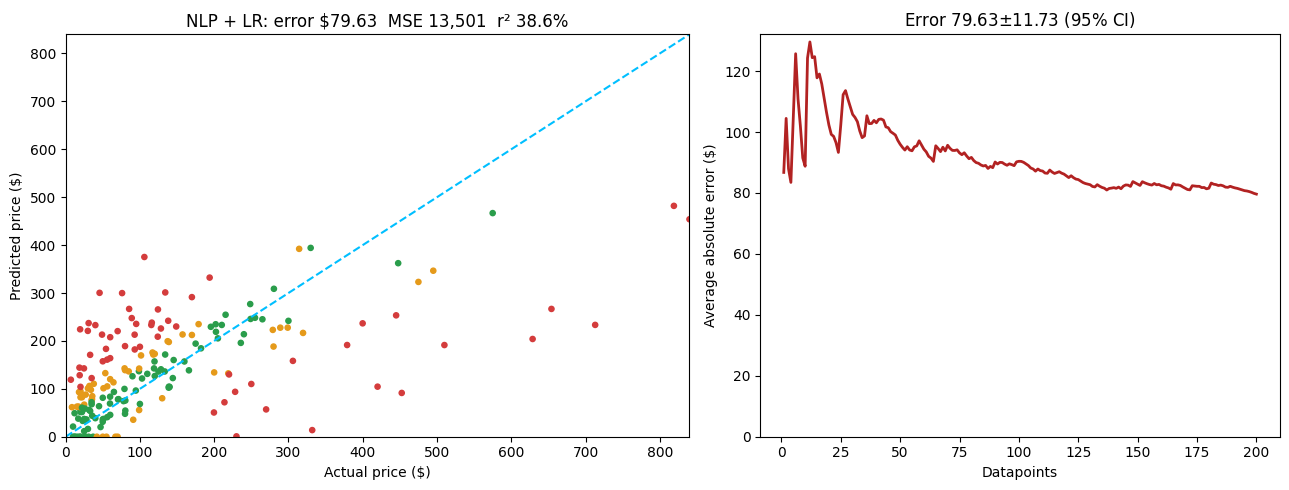

np.float64(79.62588197619577)

In [14]:
from sklearn.feature_extraction.text import CountVectorizer

prices = np.array([item.price for item in train])
documents = [item.summary for item in train]
np.random.seed(42)
vectorizer = CountVectorizer(max_features=2000, stop_words="english")
X = vectorizer.fit_transform(documents)
regressor = LinearRegression().fit(X, prices)

def natural_language_linear_regression_pricer(item):
    return max(regressor.predict(vectorizer.transform([item.summary]))[0], 0)

evaluate(natural_language_linear_regression_pricer, test, title="NLP + LR")

Trained in 12s


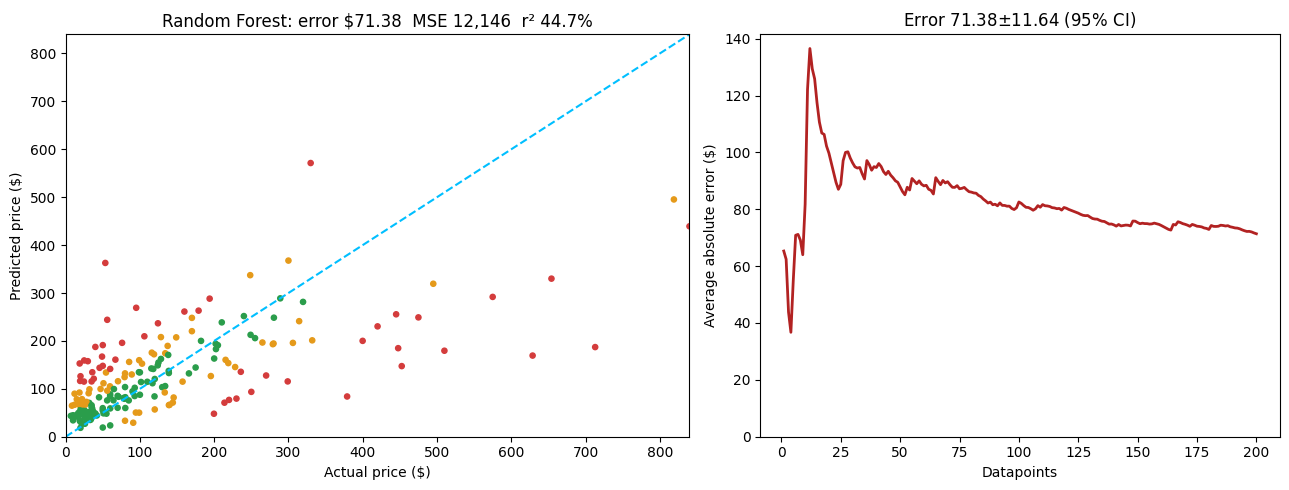

np.float64(71.38402200000004)

In [15]:
from sklearn.ensemble import RandomForestRegressor

start = time.time()
rf_model = RandomForestRegressor(n_estimators=100, random_state=42, n_jobs=-1).fit(X[:15_000], prices[:15_000])
print(f"Trained in {time.time() - start:.0f}s")

def random_forest(item):
    return max(0, rf_model.predict(vectorizer.transform([item.summary]))[0])

evaluate(random_forest, test)

XGBoost's Mac wheel looks for the OpenMP runtime (`libomp.dylib`) from Homebrew, which isn't installed here. But
torch ships its own copy and loads it on import, after which XGBoost finds it. If even that fails, scikit-learn's
`HistGradientBoostingRegressor` - the same idea of trees that each correct the last - stands in.

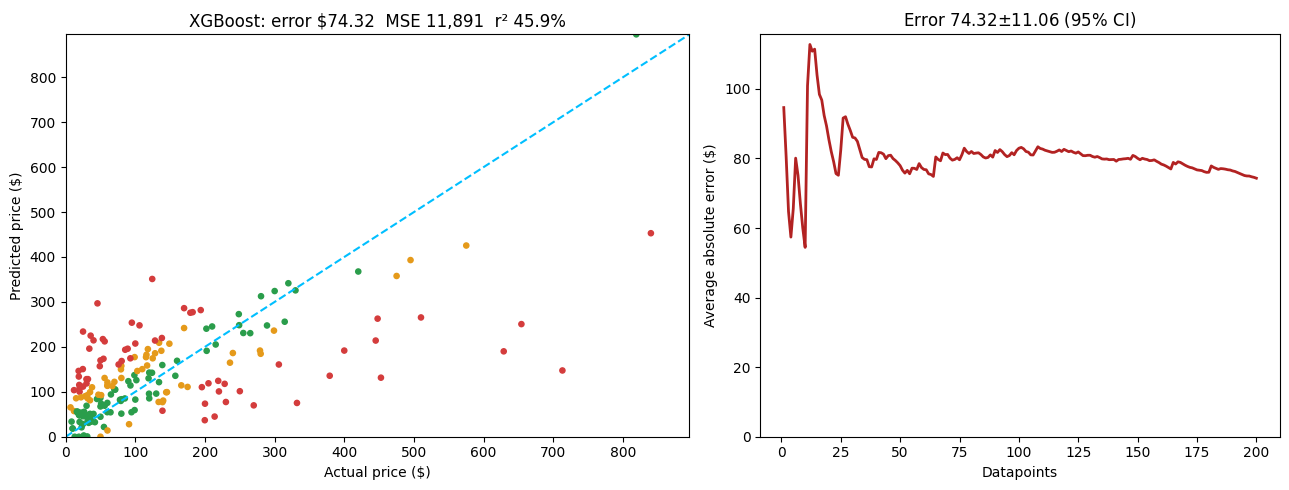

np.float32(74.32484)

In [16]:
import torch  # loads torch's libomp.dylib, which XGBoost needs and Homebrew would otherwise provide

try:
    import xgboost as xgb

    booster = xgb.XGBRegressor(n_estimators=1000, random_state=42, n_jobs=4, learning_rate=0.1).fit(X, prices)
    booster_name = "XGBoost"
    to_features = lambda texts: vectorizer.transform(texts)
except Exception as error:  # XGBoostError when libomp is missing
    print(f"XGBoost unavailable ({type(error).__name__}); using HistGradientBoostingRegressor")
    from sklearn.ensemble import HistGradientBoostingRegressor

    booster = HistGradientBoostingRegressor(max_iter=1000, learning_rate=0.1, random_state=42).fit(X.toarray(), prices)
    booster_name = "Gradient Boosting"
    to_features = lambda texts: vectorizer.transform(texts).toarray()

def gradient_boosting(item):
    return max(0, booster.predict(to_features([item.summary]))[0])

evaluate(gradient_boosting, test, title=booster_name)

## Day 4 – humans, neural networks and LLMs

`human_out.csv` holds Ed's own guesses for the first 100 test items - and they are the same products as here.

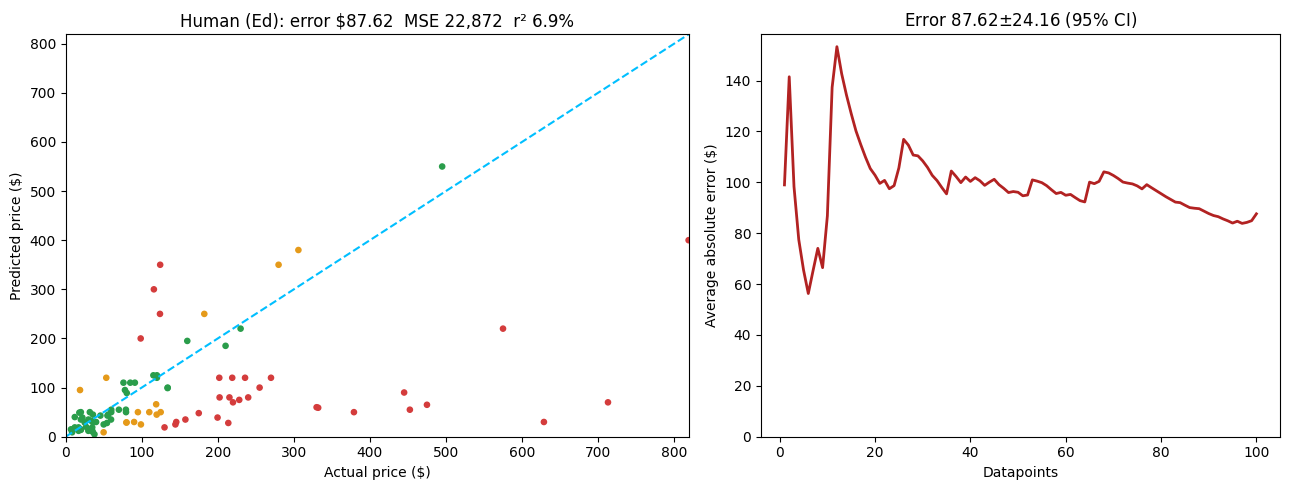

87.6223

In [17]:
human_predictions = [float(row[1]) for row in csv.reader(open("human_out.csv", encoding="utf-8"))]
human_by_summary = {item.summary: guess for item, guess in zip(test[:100], human_predictions)}

def human_pricer(item):
    return human_by_summary[item.summary]

evaluate(human_pricer, test, size=100, title="Human (Ed)")

In [18]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.feature_extraction.text import HashingVectorizer
from sklearn.model_selection import train_test_split
from torch.utils.data import DataLoader, TensorDataset

y = np.array([float(item.price) for item in train])
np.random.seed(42)
torch.manual_seed(42)
hasher = HashingVectorizer(n_features=5000, stop_words="english", binary=True)
X_hashed = hasher.fit_transform(documents)

class NeuralNetwork(nn.Module):
    def __init__(self, input_size):
        super().__init__()
        sizes = [input_size, 128, 64, 64, 64, 64, 64, 64]
        self.hidden = nn.ModuleList(nn.Linear(a, b) for a, b in zip(sizes, sizes[1:]))
        self.out = nn.Linear(64, 1)

    def forward(self, x):
        for layer in self.hidden:
            x = torch.relu(layer(x))
        return self.out(x)

X_tensor = torch.FloatTensor(X_hashed.toarray())
y_tensor = torch.FloatTensor(y).unsqueeze(1)
X_tr, X_va, y_tr, y_va = train_test_split(X_tensor, y_tensor, test_size=0.01, random_state=42)
loader = DataLoader(TensorDataset(X_tr, y_tr), batch_size=64, shuffle=True)
net = NeuralNetwork(X_tensor.shape[1])
print(f"Number of trainable parameters: {sum(p.numel() for p in net.parameters()):,}")

loss_function = nn.MSELoss()
optimizer = optim.Adam(net.parameters(), lr=0.001)
EPOCHS = 5  # the course does 2 passes over 800k items; 20k items need a few more
for epoch in range(EPOCHS):
    net.train()
    for batch_X, batch_y in loader:
        optimizer.zero_grad()
        loss = loss_function(net(batch_X), batch_y)
        loss.backward()
        optimizer.step()
    net.eval()
    with torch.no_grad():
        val_loss = loss_function(net(X_va), y_va)
    print(f"Epoch [{epoch + 1}/{EPOCHS}], Train Loss: {loss.item():.3f}, Val Loss: {val_loss.item():.3f}")

Number of trainable parameters: 669,249


Epoch [1/5], Train Loss: 38176.887, Val Loss: 19878.584


Epoch [2/5], Train Loss: 4761.042, Val Loss: 17718.244


Epoch [3/5], Train Loss: 21111.541, Val Loss: 16329.963


Epoch [4/5], Train Loss: 10529.586, Val Loss: 16680.848


Epoch [5/5], Train Loss: 7459.600, Val Loss: 16576.580


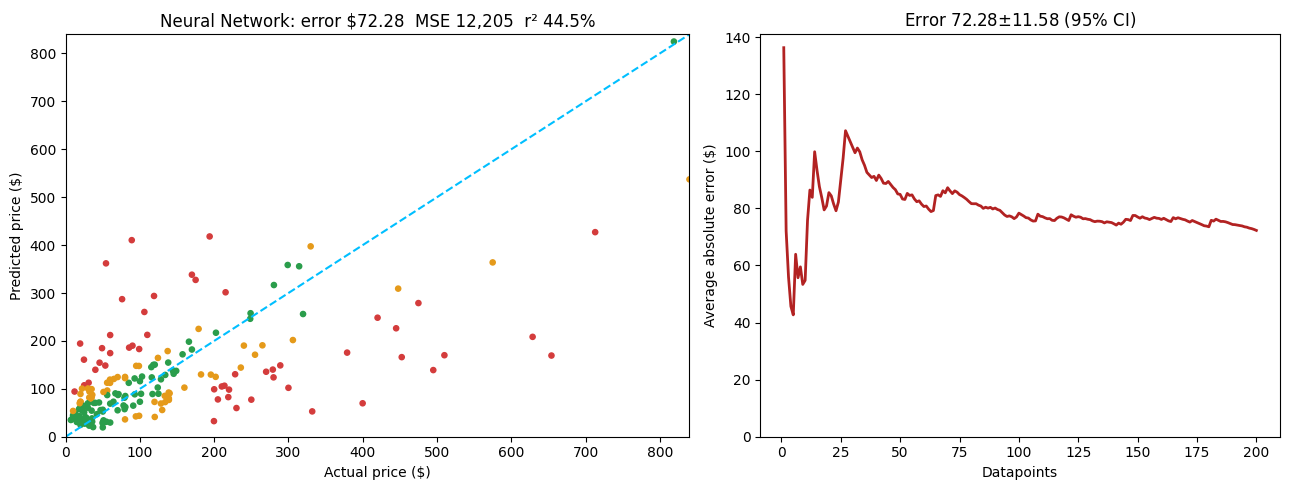

72.28466537818909

In [19]:
def neural_network(item):
    with torch.no_grad():
        vector = torch.FloatTensor(hasher.transform([item.summary]).toarray())
        return max(0, net(vector)[0].item())

evaluate(neural_network, test)

### And now - to the (local) frontier

The day 4 prompt, unchanged, sent to the two Ollama models. No training: just whatever they know about prices.

In [20]:
print(lp.price_messages(test[0])[0]["content"])
print()
print("llama3.2 says:", lp.chat(lp.price_messages(test[0]), model="llama3.2"), "| actual:", test[0].price)

Estimate the price of this product. Respond with the price, no explanation

Title: Excess V2 Distortion/Modulation Pedal  
Category: Music Pedals  
Brand: Old Blood Noise  
Description: A versatile pedal offering distortion and three modulation modes—delay, chorus, and harmonized fifths—with full control over signal routing and expression.  
Details: Features include separate gain, tone, and volume controls; time, depth, and volume per modulation; order switching, soft‑touch bypass, and expression jack for dynamic control.



llama3.2 says: $250-$300 | actual: 219.0


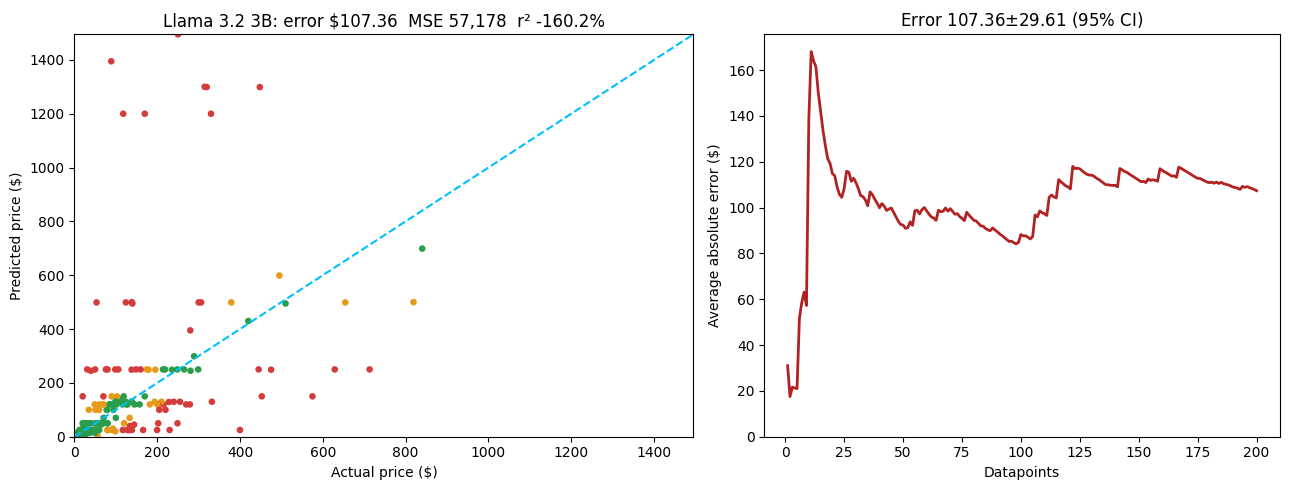

107.3558

In [21]:
evaluate(lp.llm_pricer("llama3.2"), test, workers=4, title="Llama 3.2 3B")

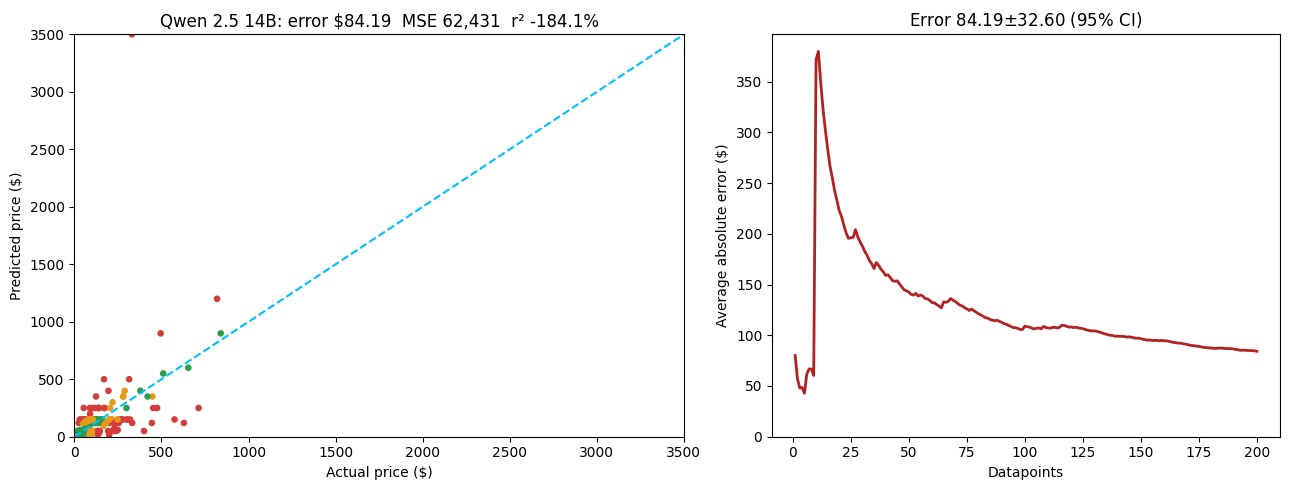

84.191

In [22]:
evaluate(lp.llm_pricer("qwen2.5:14b"), test, workers=4, title="Qwen 2.5 14B")

### Optional extra – the "redemption" deep neural network

`pricer/deep_neural_network.py`: 10 layers of 4,096 units with residual connections, trained on log prices. Ed
trained it on 800k items for four hours; on the 20k lite items it takes a few minutes on the Mac's GPU.

Deep Neural Network created with 289,128,449 parameters
Using mps


  0%|          | 0/313 [00:00<?, ?it/s]

Epoch [1/5]
Train Loss: 2.0625, Val Loss: 1.4828
Val mean absolute error: $125.44
Learning rate: 0.001000


  0%|          | 0/313 [00:00<?, ?it/s]

Epoch [2/5]
Train Loss: 0.9556, Val Loss: 0.6563
Val mean absolute error: $90.34
Learning rate: 0.000976


  0%|          | 0/313 [00:00<?, ?it/s]

Epoch [3/5]
Train Loss: 0.6942, Val Loss: 0.5812
Val mean absolute error: $80.74
Learning rate: 0.000905


  0%|          | 0/313 [00:00<?, ?it/s]

Epoch [4/5]
Train Loss: 0.5543, Val Loss: 0.5845
Val mean absolute error: $81.70
Learning rate: 0.000794


  0%|          | 0/313 [00:00<?, ?it/s]

Epoch [5/5]
Train Loss: 0.4696, Val Loss: 0.6239
Val mean absolute error: $82.97
Learning rate: 0.000655


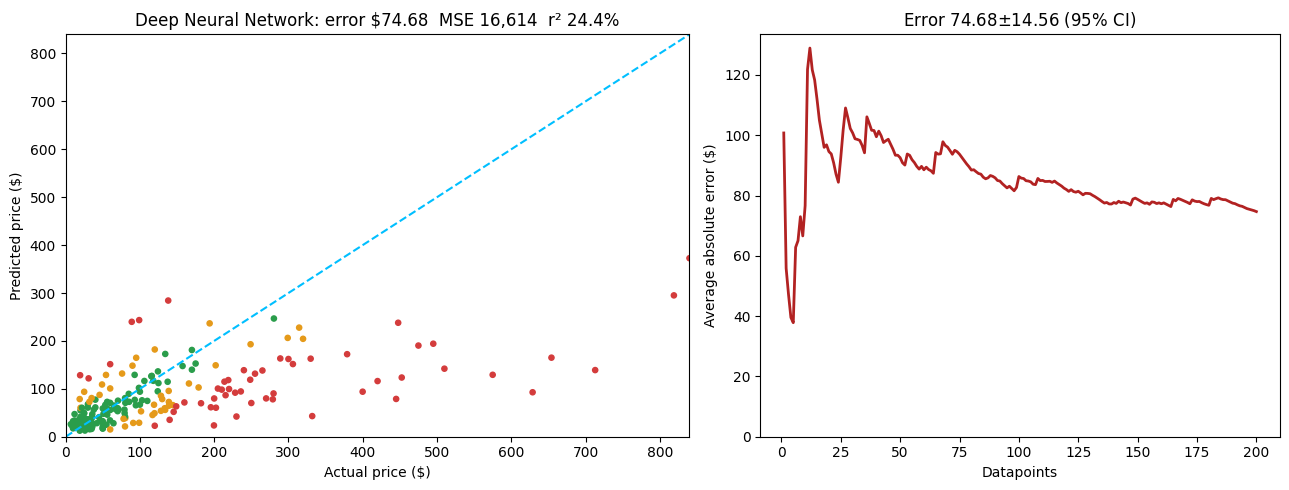

74.67884426383972

In [23]:
for model in ["llama3.2", "qwen2.5:14b"]:
    lp.unload(model)  # the 14B model holds ~9.5 GB; GPU training next to it on 24 GB swaps badly

from pricer.deep_neural_network import DeepNeuralNetworkRunner

runner = DeepNeuralNetworkRunner(train, val)
runner.setup()
runner.train(epochs=5)

def deep_neural_network(item):
    return runner.inference(item)

evaluate(deep_neural_network, test, workers=1)

In [24]:
del runner, net  # free the GPU memory before day 5
import gc; gc.collect(); torch.mps.empty_cache() if torch.backends.mps.is_available() else None

## Day 5 – fine-tuning

The course writes the training data as OpenAI chat JSONL and fine-tunes gpt-4.1-nano. The JSONL step is free and
shows the format:

In [25]:
def messages_for(item):
    message = f"Estimate the price of this product. Respond with the price, no explanation\n\n{item.summary}"
    return [{"role": "user", "content": message}, {"role": "assistant", "content": f"${item.price:.2f}"}]

def write_jsonl(items, filename):
    with open(filename, "w") as f:
        f.write("\n".join(json.dumps({"messages": messages_for(item)}) for item in items))

write_jsonl(train[:100], "jsonl/fine_tune_train.jsonl")
write_jsonl(val[:50], "jsonl/fine_tune_validation.jsonl")
print(open("jsonl/fine_tune_train.jsonl").readline()[:400])

{"messages": [{"role": "user", "content": "Estimate the price of this product. Respond with the price, no explanation\n\nTitle: Schlage F59 & 613 Andover Interior Knob (Deadbolt Included)  \nCategory: Home Hardware  \nBrand: Schlage  \nDescription: A single\u2011piece oil\u2011rubbed bronze knob that mounts to a deadbolt for secure, easy interior door use.  \nDetails: Designed for a 4\" minimum ce


Without an OpenAI key, the fine-tuning itself happens here: a **LoRA** adapter (rank 16 on every attention and MLP
projection, about 9M trainable parameters) on `Qwen2.5-0.5B-Instruct`. It learns to complete

```
What does this cost to the nearest dollar?

<summary>

Price is $
```

with the price, the prompt format the next weeks of the course use. Loss is on the price tokens only.

First, the untouched model through its chat template, as a "frontier model" baseline:

The following generation flags are not valid and may be ignored: ['temperature', 'top_p', 'top_k']. Set `TRANSFORMERS_VERBOSITY=info` for more details.


Qwen2.5-0.5B says: 1000元 | actual: 219.0


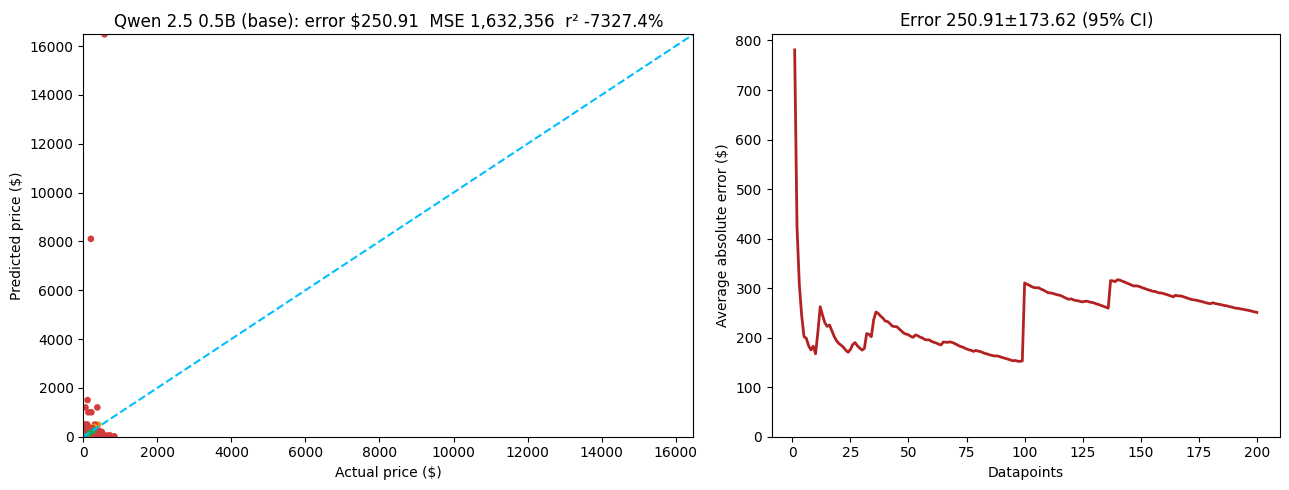

250.91095

In [26]:
pricer = lp.LoraPricer()
zero_shot = {item.summary: pricer.zero_shot(item) for item in test[:200]}
print("Qwen2.5-0.5B says:", zero_shot[test[0].summary], "| actual:", test[0].price)

def qwen2_5_0_5b(item):
    return zero_shot[item.summary]

evaluate(qwen2_5_0_5b, test, title="Qwen 2.5 0.5B (base)")

### Ed's experiment: 100 examples, 1 epoch

The course fine-tunes on 100 examples (OpenAI's suggested 50–100) and the result is *worse* than the base model's.
The same with LoRA takes seconds:

LoRA adapter: 8,798,208 trainable parameters of 502,830,976 (1.75%)


LoRA training:   0%|          | 0/7 [00:00<?, ?it/s]

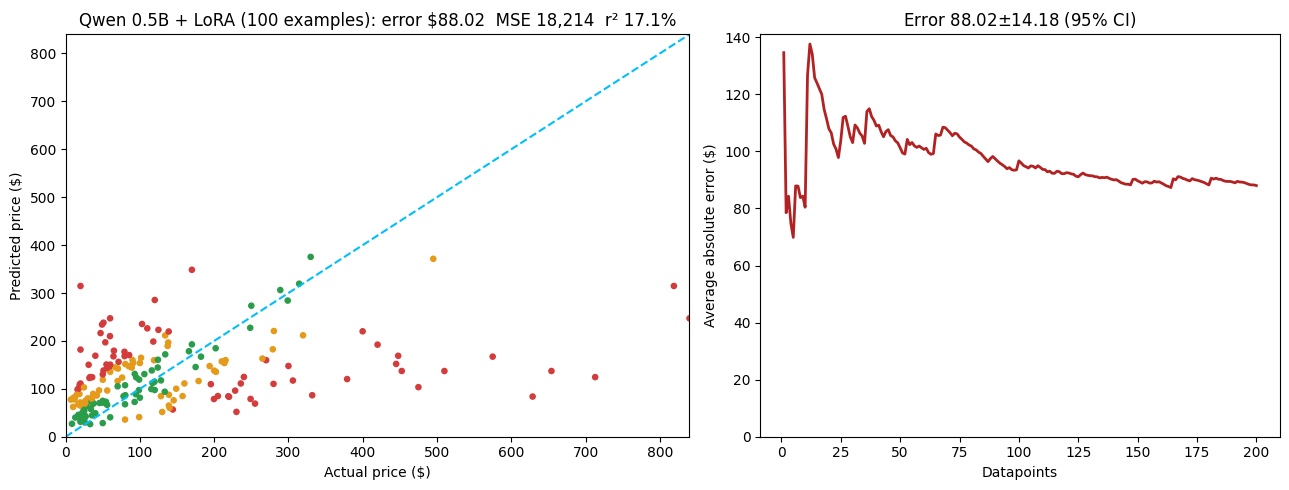

In [27]:
small = lp.LoraPricer()
small.train(train[:100], epochs=1, batch_size=16, warmup=2, log_every=1)
small_predictions = dict(zip([i.summary for i in test[:200]], small.predict_many(test[:200])))

def lora_100_examples(item):
    return small_predictions[item.summary]

evaluate(lora_100_examples, test, title="Qwen 0.5B + LoRA (100 examples)")
del small

### All 20,000 training items

One epoch takes about 40 minutes, so it runs outside the notebook - `uv run python local_pricer.py` - and saves the
adapter (35 MB) to `models/qwen-pricer/`. The cell below trains it here instead if the adapter isn't there yet.

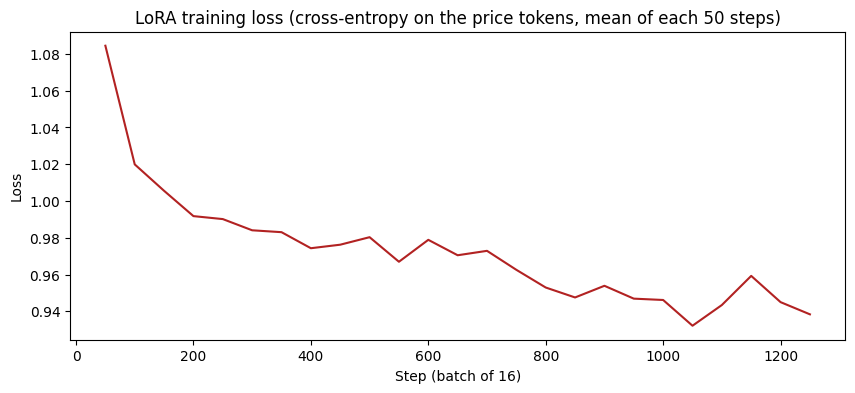

In [28]:
history_file = lp.ADAPTER_DIR / "history.json"
if (lp.ADAPTER_DIR / "adapter_config.json").exists():
    pricer.load()
    history = json.loads(history_file.read_text())["loss_every_50_steps"]
else:
    history = pricer.train(train)
    pricer.save()
    history_file.write_text(json.dumps({"items": len(train), "loss_every_50_steps": history}))

plt.figure(figsize=(10, 4))
plt.plot(np.arange(1, len(history) + 1) * 50, history, color="firebrick")
plt.title("LoRA training loss (cross-entropy on the price tokens, mean of each 50 steps)")
plt.xlabel("Step (batch of 16)")
plt.ylabel("Loss")
plt.show()

Decoding matters. Greedy decoding picks the likeliest digit one position at a time; asking for the 8 best candidate
numbers (beam search) and averaging them by probability gives a better estimate from the same adapter:

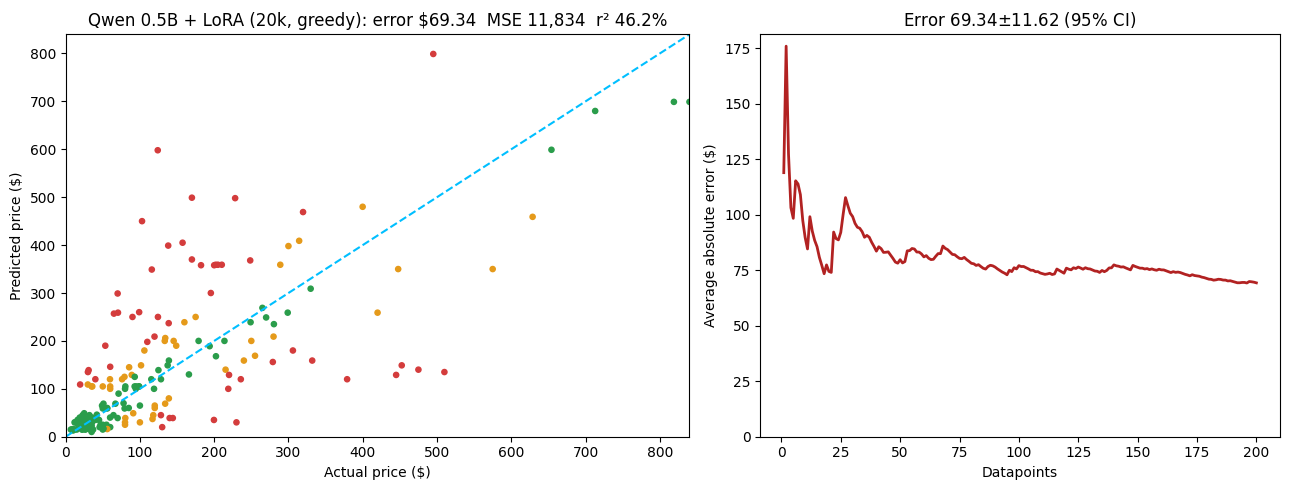

69.34135

In [29]:
summaries = [i.summary for i in test[:200]]
greedy = dict(zip(summaries, pricer.predict_many(test[:200], beams=1)))

def qwen_lora_greedy(item):
    return greedy[item.summary]

evaluate(qwen_lora_greedy, test, title="Qwen 0.5B + LoRA (20k, greedy)")

200 predictions in 88s
$   148  vs  $ 219.00  Old Blood Noise Excess V2 Distortion Chorus/Delay Pedal
$   171  vs  $ 115.99  telpo Headlight Assembly Fit For 15 Camry 16 Camry 17 Toyota
$    33  vs  $  54.95  NewPower99 Battery Kit for Samsung Galaxy Tab S3 9.7 SM-T820
$    48  vs  $  69.98  EXMAX NG-10X Fresnel Lens Focusing Adapter Fresnel Spot S-Mo
$    82  vs  $  29.85  Stand for Raven Pro Document Scanner - Provides Better Seate


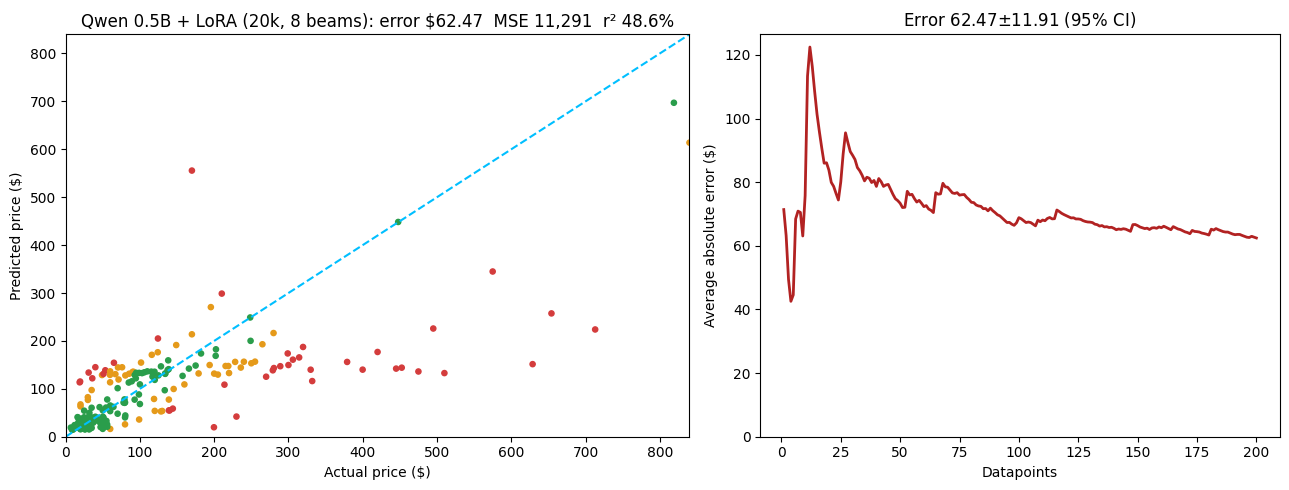

62.47202293000137

In [30]:
start = time.time()
fine_tuned = dict(zip(summaries, pricer.predict_many(test[:200], beams=8)))
print(f"200 predictions in {time.time() - start:.0f}s")
for item in test[:5]:
    print(f"${fine_tuned[item.summary]:>6.0f}  vs  ${item.price:>7.2f}  {item.title[:60]}")

def qwen_lora_fine_tuned(item):
    return fine_tuned[item.summary]

evaluate(qwen_lora_fine_tuned, test, title="Qwen 0.5B + LoRA (20k, 8 beams)")

## Results

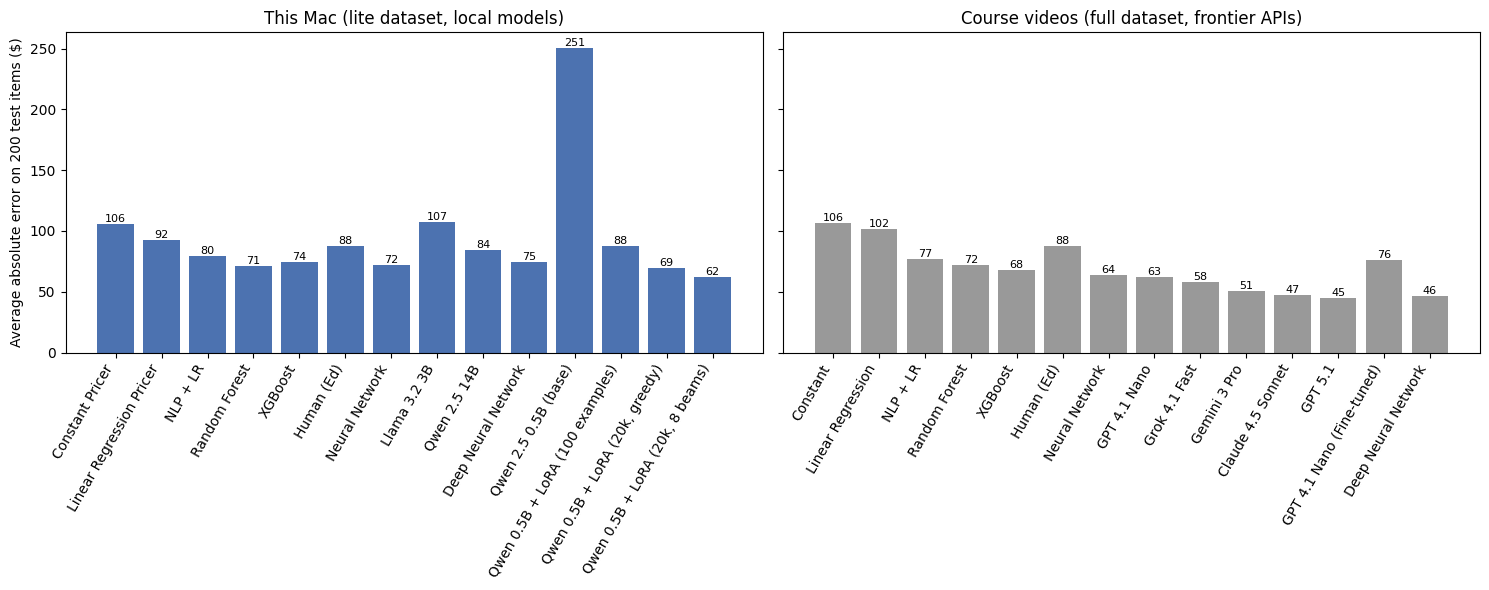

,error ($)
"Qwen 0.5B + LoRA (20k, 8 beams)",62.47
"Qwen 0.5B + LoRA (20k, greedy)",69.34
Random Forest,71.38
Neural Network,72.28
XGBoost,74.32
Deep Neural Network,74.68
NLP + LR,79.63
Qwen 2.5 14B,84.19
Human (Ed),87.62
Qwen 0.5B + LoRA (100 examples),88.02


In [31]:
lp.results_chart({k: v for k, v in RESULTS.items() if k != "Random Pricer"})
pd.DataFrame({"error ($)": RESULTS}).round(2).sort_values("error ($)")

### What this shows

Same 200 test products as the videos; the difference is 20k training items instead of 800k, and local models
instead of frontier APIs.

- **Traditional ML tracks the course.** Constant \$106 (Ed \$106), bag-of-words regression \$80 (\$77), random forest
  \$71 (\$72 - his also trained on 15k items). The models that Ed fed 800k items fall behind on 20k: XGBoost \$74
  (\$68), the small neural network \$72 (\$64) and above all the deep network, \$75 against his \$46 - its 289M
  parameters start overfitting 20k items after three epochs (validation error rises again).
- **Local LLMs know much less about prices than frontier ones.** Llama 3.2 3B (\$107) is no better than always
  guessing the average, and Qwen 2.5 14B (\$84) is only just ahead of Ed guessing by hand (\$88) - GPT-5.1 got \$45.
- **Fine-tuning flips the course's result.** Ed's fine-tuned gpt-4.1-nano came out *worse* than the untouched one,
  because a frontier model already knows prices and a few thousand examples mostly disturb it. Qwen 0.5B knows
  nothing about prices (\$251 - it answered the first product with "1000元"), so the data teaches it a lot: 100
  examples bring it to \$88, and 20,000 examples to **\$62**, the best score here, level with Ed's zero-shot
  gpt-4.1-nano and well ahead of a 14B model thirty times its size.
- **Decoding matters too:** the same adapter scores \$69 with greedy decoding and \$62 when the 8 best candidate
  numbers are averaged by probability.

The week's exercise uses this adapter as the opponent in a Spanish price-guessing game:
[precio_justo.py](precio_justo.py).